# Bab 4 — Regression and Prediction

**Rujukan:** buku utama edisi 2, Bab 4. `LungDisease.csv` dari repositori pendamping dipakai untuk regresi sederhana. Untuk memperlihatkan banyak prediktor, interaksi dan spline tanpa dataset eksternal besar, bagian lanjutan memakai dataset diabetes yang dibundel scikit-learn. Kode dan uraian ditulis mandiri. Tidak ada neural network di bab ini.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import train_test_split, cross_validate, KFold
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures, SplineTransformer, StandardScaler
from sklearn.pipeline import make_pipeline

ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
lung = pd.read_csv(ROOT / 'data' / 'LungDisease.csv')
lung.describe().round(2)

mkdir -p failed for path C:\Users\Rangga Timotius\AppData\Local\matplotlib: [WinError 5] Access is denied: 'C:\\Users\\Rangga Timotius\\AppData\\Local\\matplotlib'


Matplotlib created a temporary cache directory at C:\Users\RANGGA~1\AppData\Local\Temp\matplotlib-2vxry10s because there was an issue with the default path (C:\Users\Rangga Timotius\AppData\Local\matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


,PEFR,Exposure
count,122.00,122.00
mean,365.66,14.08
std,105.13,6.96
min,110.00,0.00
25%,300.00,7.00
50%,365.00,17.00
75%,430.00,20.00
max,610.00,23.00


## 1. Regresi linear sederhana

Model $y_i=\beta_0+\beta_1x_i+\epsilon_i$ menghubungkan paparan (`Exposure`) dengan fungsi paru (`PEFR`). Ordinary least squares memilih koefisien yang meminimalkan jumlah kuadrat residual. Slope menyatakan perubahan prediksi outcome untuk kenaikan satu unit prediktor, **bukan** efek kausal tanpa desain dan asumsi tambahan. Hubungan bisa dipengaruhi confounder yang tidak dicatat.

Intercept: 424.58 slope: -4.185


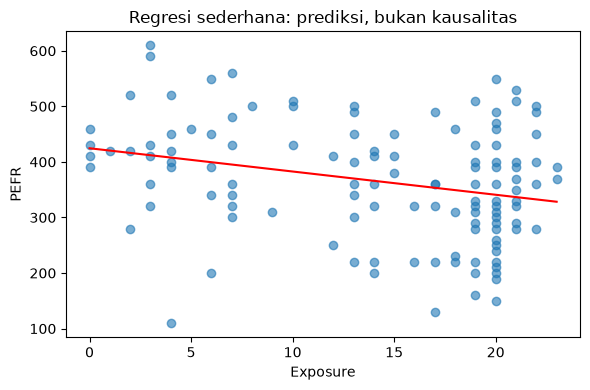

In [2]:
simple = LinearRegression().fit(lung[['Exposure']], lung['PEFR'])
print('Intercept:', round(simple.intercept_, 2), 'slope:', round(simple.coef_[0], 3))
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(lung['Exposure'], lung['PEFR'], alpha=.6)
xx = np.linspace(lung.Exposure.min(), lung.Exposure.max(), 100)
ax.plot(xx, simple.predict(pd.DataFrame({'Exposure': xx})), color='red')
ax.set(xlabel='Exposure', ylabel='PEFR', title='Regresi sederhana: prediksi, bukan kausalitas')
plt.tight_layout(); plt.show()

## 2. Residual dan diagnosis awal

Residual $e_i=y_i-\hat y_i$. Pola melengkung mengisyaratkan hubungan tidak linear; bentuk kipas dapat menunjukkan heteroskedastisitas; titik jauh bisa berpengaruh besar. Plot residual bukan uji final, tetapi pemeriksaan awal yang wajib. Ekstrapolasi di luar rentang paparan yang diamati memiliki ketidakpastian lebih tinggi.

RMSE in-sample: 100.6


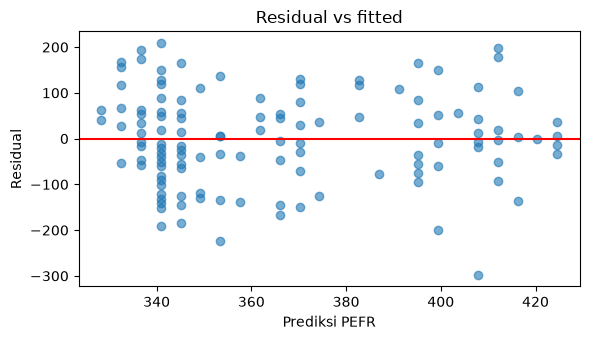

In [3]:
fitted = simple.predict(lung[['Exposure']])
residual = lung['PEFR'].to_numpy() - fitted
print('RMSE in-sample:', round(root_mean_squared_error(lung['PEFR'], fitted), 2))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.scatter(fitted, residual, alpha=.6); ax.axhline(0, color='red')
ax.set(xlabel='Prediksi PEFR', ylabel='Residual', title='Residual vs fitted')
plt.tight_layout(); plt.show()

## 3. Regresi multiple dan validasi di data tak terlihat

Beberapa prediktor memungkinkan estimasi asosiasi *kondisional*: koefisien satu fitur dibaca dengan fitur lain tetap. Multikolinearitas dapat membuat koefisien tidak stabil. Train/test split memisahkan evaluasi dari fitting; cross-validation mengulang pembagian agar estimasi kinerja lebih stabil. Model, transformasi, dan pilihan fitur seharusnya dipilih hanya dari training/CV; test set disimpan sebagai pemeriksaan akhir. Metrik MAE dan RMSE berada dalam unit outcome; RMSE memberi penalti lebih besar pada error besar.

In [4]:
diabetes = load_diabetes(as_frame=True)
X, y = diabetes.data, diabetes.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=42)
ols = LinearRegression().fit(X_train, y_train)
pred = ols.predict(X_test)
print(pd.Series({'test_MAE': mean_absolute_error(y_test, pred),
                 'test_RMSE': root_mean_squared_error(y_test, pred),
                 'test_R2': r2_score(y_test, pred)}).round(3))
cv = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_validate(LinearRegression(), X_train, y_train, cv=cv,
                        scoring={'mae': 'neg_mean_absolute_error', 'r2': 'r2'})
print('CV MAE:', round(-scores['test_mae'].mean(), 2), 'CV R2:', round(scores['test_r2'].mean(), 3))

test_MAE     42.794
test_RMSE    53.853
test_R2       0.453
dtype: float64
CV MAE: 45.05 CV R2: 0.48


## 4. Variabel kategori dan interaksi

Kategori harus diubah menjadi indikator (*dummy*) dengan satu level referensi untuk menghindari ketergantungan linear sempurna bersama intercept. Interaksi memungkinkan slope satu prediktor berubah menurut prediktor lain. Di sini kelompok BMI dibuat **khusus demonstrasi** dari median training; ambang yang dipelajari pada seluruh data sebelum split akan menyebabkan leakage. Contoh ini bukan model medis yang siap pakai.

In [5]:
threshold = X_train['bmi'].median()
def design(frame):
    out = frame[['age', 'bmi', 'bp']].copy()
    out['high_bmi'] = (frame['bmi'] > threshold).astype(int)
    out['age_x_high_bmi'] = out['age'] * out['high_bmi']
    return out

interaction = LinearRegression().fit(design(X_train), y_train)
print('Interaction model test RMSE:', round(root_mean_squared_error(y_test, interaction.predict(design(X_test))), 2))
print(pd.Series(interaction.coef_, index=design(X_train).columns).round(2))

Interaction model test RMSE: 61.01
age                -0.96
bmi               796.44
bp                375.68
high_bmi            5.50
age_x_high_bmi    113.18
dtype: float64


## 5. Regularisasi, model selection, dan bias–variance

Menambah prediktor selalu bisa menurunkan error training OLS, tetapi tidak menjamin prediksi baru lebih baik. Ridge menambah penalti $\lambda\sum_j\beta_j^2$ sehingga koefisien menyusut; standardisasi dimasukkan **di dalam pipeline** agar tiap fold CV mempelajari parameter scaler dari training fold saja. Grid kecil ini dipilih dengan CV training; metrik test dihitung sekali setelah pemilihan.

In [6]:
candidates = [0.1, 1.0, 10.0, 100.0]
rows = []
for alpha in candidates:
    model = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    cv_result = cross_validate(model, X_train, y_train, cv=cv, scoring='neg_root_mean_squared_error')
    rows.append({'alpha': alpha, 'CV_RMSE': -cv_result['test_score'].mean()})
selection = pd.DataFrame(rows).sort_values('CV_RMSE')
best_alpha = float(selection.iloc[0]['alpha'])
best = make_pipeline(StandardScaler(), Ridge(alpha=best_alpha)).fit(X_train, y_train)
print(selection.round(2).to_string(index=False))
print('Selected Ridge test RMSE:', round(root_mean_squared_error(y_test, best.predict(X_test)), 2))

 alpha  CV_RMSE
   1.0    55.37
   0.1    55.39
  10.0    55.44
 100.0    56.00
Selected Ridge test RMSE: 53.78


## 6. Kurva non-linear: polinomial dan spline

Regresi masih bisa linear dalam **koefisien** walaupun fitur adalah fungsi non-linear dari $x$. Polinomial derajat tinggi mudah berosilasi di batas. Spline membagi rentang $x$ menjadi beberapa bagian polinomial halus. Keduanya perlu memilih kompleksitas lewat validasi; grafik berikut hanya eksplorasi *in-sample* pada hubungan BMI–outcome, bukan bukti bahwa model terbaik untuk prediksi.

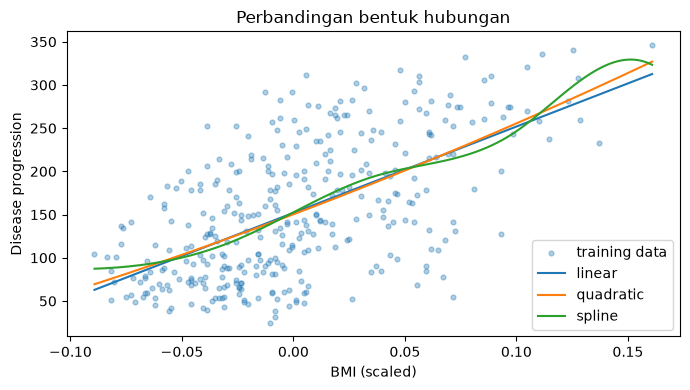

In [7]:
bmi = X_train[['bmi']]
curves = {
    'linear': LinearRegression(),
    'quadratic': make_pipeline(PolynomialFeatures(2, include_bias=False), LinearRegression()),
    'spline': make_pipeline(SplineTransformer(n_knots=5, degree=3), LinearRegression()),
}
grid = pd.DataFrame({'bmi': np.linspace(bmi.bmi.min(), bmi.bmi.max(), 200)})
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(bmi.bmi, y_train, s=12, alpha=.35, label='training data')
for label, model in curves.items():
    model.fit(bmi, y_train)
    ax.plot(grid.bmi, model.predict(grid), label=label)
ax.set(xlabel='BMI (scaled)', ylabel='Disease progression', title='Perbandingan bentuk hubungan')
ax.legend(); plt.tight_layout(); plt.show()

### Ringkasan dan refleksi

- Bedakan tujuan **prediksi** (kinerja pada data baru) dari **inferensi** (interpretasi koefisien/asumsi).
- Periksa residual, titik berpengaruh, non-linearitas, heteroskedastisitas, dan kemungkinan confounding.
- CV untuk memilih model; test set hanya untuk evaluasi final, dengan semua transformasi dilatih di training fold.
- Bab ini memakai model statistik klasik, bukan deep learning. Penamaan repo mengikuti konteks kelas.